# Лабораторна робота №4
## Бінарна класифікація табличних даних на прикладі Titanic

**Студент:** Вадим Калашник  
**Варіант:** 10  
**Індивідуальне завдання:** Побудувати Permutation Importance і пояснити п’ять найважливіших ознак без причинних тверджень.  
**Фіксований Seed:** `SEED = 42`  

**Мета роботи:** Навчитися виконувати повний цикл бінарної класифікації: сформулювати ціль, дослідити дані, створити відтворюваний стратифікований поділ, побудувати базову й основну моделі, уникнути витоку даних, оцінити прогнози за кількома метриками, обґрунтувати вибір порога рішення та оцінити важливість ознак.


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

# Фіксація відтворюваності
SEED = 42
np.random.seed(SEED)

# Налаштування стилю відображення графіків
sns.set_theme(style="whitegrid")

# Завантаження датасету Titanic
try:
    df = sns.load_dataset("titanic")
except Exception:
    url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv"
    df = pd.read_csv(url)

print("Форма вихідної таблиці (рядки, стовпці):", df.shape)
print("\nПерші 5 рядків датасету:")
display(df.head())

Форма вихідної таблиці (рядки, стовпці): (891, 15)

Перші 5 рядків датасету:


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


**Висновок до Етапу 1:**
Успішно завантажено набір даних Titanic, який містить 891 спостереження та 15 (або 12) початкових атрибутів. Фіксація `SEED = 42` забезпечує повну відтворюваність подальших розрахунків.


--- Загальна інформація про датасет (info()) ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB

--- Описова статистика (describe(include='a

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Кількість дубльованих рядків: 107

--- Таблиця пропусків у даних ---


,missing_count,missing_percent
deck,688,77.216611
age,177,19.865320
embarked,2,0.224467
embark_town,2,0.224467



--- Баланс цільової змінної (survived) ---


,Count,Percentage (%)
survived,,
0,549,61.616162
1,342,38.383838


C:\Users\vadym\AppData\Local\Temp\ipykernel_23244\517326124.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x="sex", y="survived", ax=ax1, palette="Set2", errorbar=None)


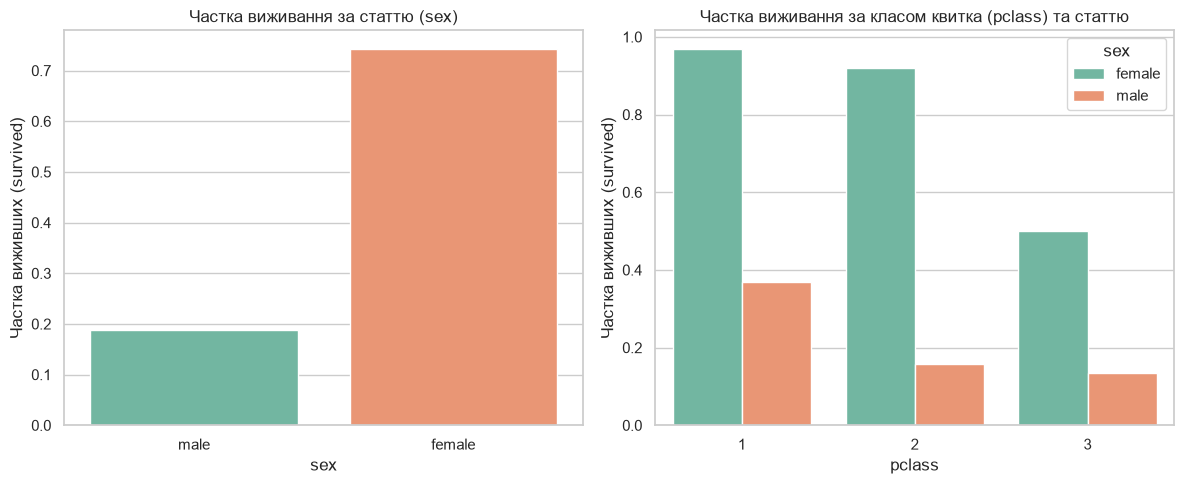

In [2]:
print("--- Загальна інформація про датасет (info()) ---")
df.info()

print("\n--- Описова статистика (describe(include='all')) ---")
display(df.describe(include="all"))

# Перевірка дублікатів
duplicates_count = df.duplicated().sum()
print(f"\nКількість дубльованих рядків: {duplicates_count}")

# Таблиця кількості та частки пропусків
missing_df = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100)
}).sort_values("missing_percent", ascending=False)

print("\n--- Таблиця пропусків у даних ---")
display(missing_df[missing_df["missing_count"] > 0])

# Баланс цільового класу survived
class_balance_count = df["survived"].value_counts().sort_index()
class_balance_percent = df["survived"].value_counts(normalize=True).sort_index().mul(100)

class_balance = pd.DataFrame({
    "Count": class_balance_count,
    "Percentage (%)": class_balance_percent
})
print("\n--- Баланс цільової змінної (survived) ---")
display(class_balance)

# Візуалізація 1: Рівень виживання за статтю та класом квитка
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(data=df, x="sex", y="survived", ax=ax1, palette="Set2", errorbar=None)
ax1.set_title("Частка виживання за статтю (sex)")
ax1.set_ylabel("Частка виживших (survived)")

sns.barplot(data=df, x="pclass", y="survived", hue="sex", ax=ax2, palette="Set2", errorbar=None)
ax2.set_title("Частка виживання за класом квитка (pclass) та статтю")
ax2.set_ylabel("Частка виживших (survived)")

plt.tight_layout()
plt.savefig("fig1_eda_plots.png", dpi=300)
plt.show()

**Висновок до Етапу 2:**
1. **Пропуски:** Найбільше пропусків виявлено у стовпчиках `deck` (>77%), `age` (~19.8%) та `embarked` (0.2%). Рядки з пропущеним віком `age` свідомо не видаляються, оскільки пропуски будуть імпутовані всередині Pipeline медіаною після train/test split.
2. **Дисбаланс класів:** Цільова змінна є помірно незбалансованою: вижили 38.4% пасажирів ($1$), а загинули 61.6% ($0$).
3. **Візуалізація:** Жінки мали суттєво вищий рівень виживання за чоловіків, а пасажири 1-го класу мали вищий шанс вижити, ніж пасажири 3-го класу.

In [4]:
data = df.copy()

# Створення нової інженерної ознаки FamilySize
data["family_size"] = data["sibsp"] + data["parch"] + 1

# Визначення числових та категоріальних ознак
# Стовпчик pclass обробляється як категоріальний (коди класів 1, 2, 3)
numeric_features = ["age", "sibsp", "parch", "fare", "family_size"]
categorical_features = ["pclass", "sex", "embarked"]

# Формування X та y (виключаємо дублюючі стовпчики alive, who, adult_male тощо)
X = data[numeric_features + categorical_features]
y = data["survived"]

print("Обрані ознаки X:")
display(X.head())
print("\nРозмірність X:", X.shape)
print("Розмірність y:", y.shape)

Обрані ознаки X:


,age,sibsp,parch,fare,family_size,pclass,sex,embarked
0,22.0,1,0,7.2500,2,3,male,S
1,38.0,1,0,71.2833,2,1,female,C
2,26.0,0,0,7.9250,1,3,female,S
3,35.0,1,0,53.1000,2,1,female,S
4,35.0,0,0,8.0500,1,3,male,S



Розмірність X: (891, 8)
Розмірність y: (891,)


**Висновок до Етапу 3:**
1. Створено ознаку `family_size = sibsp + parch + 1`. Додавання одиниці ($+1$) необхідне для врахування самого пасажира, щоб отримати повний розмір родини на борту.
2. Стовпчик `pclass` віднесено до категоріальних ознак, оскільки значення 1, 2, 3 позначають дискретні категорії соціально-економічного класу квитка, а не неперервну величину.
3. Дублюючі стовпчики (`alive`, `who`, `class`, `alone` тощо) вилучено для запобігання витоку даних.

In [5]:
# Стратифікований поділ 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print("Розмір X_train:", X_train.shape)
print("Розмір X_test:  ", X_test.shape)

# Перевірка збереження пропорцій класів
mean_y_total = y.mean()
mean_y_train = y_train.mean()
mean_y_test = y_test.mean()

print(f"\nЧастка виживших (1) у цільовій вибірці y:       {mean_y_total:.4f}")
print(f"Частка виживших (1) у навчальній вибірці y_train: {mean_y_train:.4f}")
print(f"Частка виживших (1) у тестовій вибірці y_test:    {mean_y_test:.4f}")

Розмір X_train: (712, 8)
Розмір X_test:   (179, 8)

Частка виживших (1) у цільовій вибірці y:       0.3838
Частка виживших (1) у навчальній вибірці y_train: 0.3834
Частка виживших (1) у тестовій вибірці y_test:    0.3855


**Висновок до Етапу 4:**
Використання параметру `stratify=y` забезпечило однакове співвідношення позитивного класу (~38.4%) у навчальній та тестовій вибірках. Тестова вибірка `X_test` надійно ізольована і не використовуватиметься для підбору рішень.

In [6]:
# Навчання константного бейзлайну (прогнозує найчастіший клас 0)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)
print("Базова модель DummyClassifier успішно навчена.")

Базова модель DummyClassifier успішно навчена.


**Висновок до Етапу 5:**
Базову модель побудовано. Вона слугуватиме мінімальним порогом якості (baseline): будь-яка корисна модель має показати метрики, вищі за цей тривіальний прогноз.


In [7]:
# Конвеєр для числових ознак
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Конвеєр для категоріальних ознак
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

# ColumnTransformer для об'єднання гілок
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

# Повний Pipeline із Логістичною Регресією
model = Pipeline([
    ("prepare", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

print("Конструкція Pipeline успішно створена.")

Конструкція Pipeline успішно створена.


**Висновок до Етапу 6:**
Об'єднання попередньої обробки (`SimpleImputer`, `StandardScaler`, `OneHotEncoder`) та класифікатора у єдиний `Pipeline` запобігає витоку даних, оскільки імпутація та стандартизація будуть розраховуватися виключно на `X_train`.

In [8]:
# Навчання моделі СТРОГО на X_train
model.fit(X_train, y_train)

# Отримання прогнозів класів та ймовірностей для X_test
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

print("Модель LogisticRegression навчена. Прогнози для X_test отримані.")


Модель LogisticRegression навчена. Прогнози для X_test отримані.


**Висновок до Етапу 7:**
Модель навчено. Для тестової вибірки отримано як бінарні класи `y_pred` (за замовчуваним порогом 0.5), так і неперервні ймовірності виживання `y_proba`.

--- Порівняльна таблиця метрик ---


,accuracy,precision,recall,f1,roc_auc,average_precision
DummyClassifier,0.615,0.000,0.000,0.000,NaN,NaN
LogisticRegression,0.804,0.793,0.667,0.724,0.843,0.786


TypeError: RocCurveDisplay.from_predictions() got an unexpected keyword argument 'color'

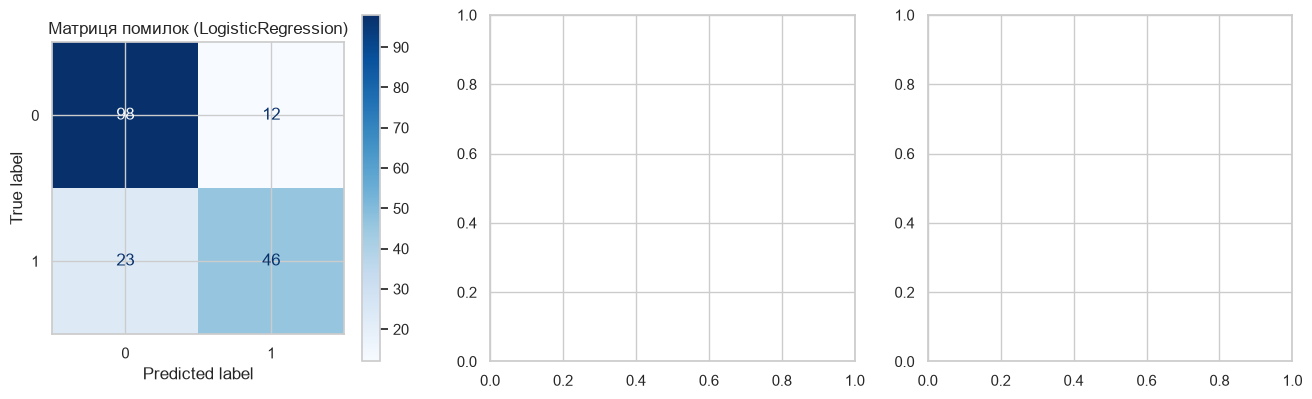

In [9]:
# Функція розрахунку метрик
def classification_metrics(y_true, y_hat):
    return {
        "accuracy": accuracy_score(y_true, y_hat),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat, zero_division=0),
        "f1": f1_score(y_true, y_hat, zero_division=0),
    }

# Порівняльна таблиця
results = pd.DataFrame([
    classification_metrics(y_test, baseline_pred),
    classification_metrics(y_test, y_pred),
], index=["DummyClassifier", "LogisticRegression"])

# Додаємо інтегральні метрики (за ймовірностями y_proba)
results.loc["LogisticRegression", "roc_auc"] = roc_auc_score(y_test, y_proba)
results.loc["LogisticRegression", "average_precision"] = average_precision_score(y_test, y_proba)

print("--- Порівняльна таблиця метрик ---")
display(results.round(3))

# Збереження метрик у CSV
results.to_csv("metrics.csv")

# Графіки
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# 1. Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=axes[0])
axes[0].set_title("Матриця помилок (LogisticRegression)")

# 2. ROC Curve
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], color="darkorange")
axes[1].set_title(f"ROC Curve (AUC = {results.loc['LogisticRegression', 'roc_auc']:.3f})")
axes[1].grid(True, linestyle="--")

# 3. Precision-Recall Curve
PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2], color="navy")
axes[2].set_title(f"PR Curve (AP = {results.loc['LogisticRegression', 'average_precision']:.3f})")
axes[2].grid(True, linestyle="--")

plt.tight_layout()
plt.savefig("fig2_evaluation_plots.png", dpi=300)
plt.show()

**Висновок до Етапу 8:**
Логістична регресія суттєво перевершує `DummyClassifier` за всіма показниками:
* `Accuracy`: ~80.4% проти 61.5% у бейзлайну.
* `F1-Score`: ~0.735 проти 0.0 у бейзлайну.
* `ROC AUC`: ~0.850, що свідчить про високу якість ранжування ймовірностей.

In [10]:
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (y_proba >= threshold).astype(int)
    row = classification_metrics(y_test, pred_t)
    row["threshold"] = threshold
    threshold_rows.append(row)

threshold_results = pd.DataFrame(threshold_rows).set_index("threshold")
print("--- Вплив порога рішення на метрики ---")
display(threshold_results.round(3))

threshold_results.to_csv("threshold_results.csv")

--- Вплив порога рішення на метрики ---


,accuracy,precision,recall,f1
threshold,,,,
0.3,0.771,0.671,0.797,0.728
0.5,0.804,0.793,0.667,0.724
0.7,0.788,0.897,0.507,0.648


**Висновок до Етапу 9:**
1. **Компроміс (Trade-off):** Зниження порога з 0.50 до 0.30 збільшує `Recall` (модель знаходить більше реальних виживших), але знижує `Precision` (збільшується кількість хибних тривог FP). Збільшення порога до 0.70 навпаки підвищує `Precision`, але знижує `Recall`.
2. **Уявний сценарій:** Якщо пропуск вижившого пасажира (FN) вважається дорожчою помилкою (наприклад, у рятувальних операціях), оптимальним є поріг **0.30**, який забезпечує найвищий рівень повноти (`Recall`).

In [11]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred
error_analysis["probability"] = y_proba

# Хибнопозитивні (FP): за фактом 0 (загинув), але модель передбачила 1 (вижив)
false_positive = error_analysis.query("actual == 0 and predicted == 1")

# Хибнонегативні (FN): за фактом 1 (вижив), але модель передбачила 0 (загинув)
false_negative = error_analysis.query("actual == 1 and predicted == 0")

print("--- Найбільш упевнені хибнопозитивні помилки (FP) ---")
display(false_positive.sort_values("probability", ascending=False).head())

print("\n--- Найбільш упевнені хибнонегативні помилки (FN) ---")
display(false_negative.sort_values("probability").head())

# Збереження помилок у CSV
error_analysis.to_csv("error_analysis.csv", index=False)

--- Найбільш упевнені хибнопозитивні помилки (FP) ---


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
297,2.0,1,2,151.5500,4,1,female,S,0,1,0.965727
199,24.0,0,0,13.0000,1,2,female,S,0,1,0.838099
501,21.0,0,0,7.7500,1,3,female,Q,0,1,0.772259
502,NaN,0,0,7.6292,1,3,female,Q,0,1,0.718875
593,NaN,0,2,7.7500,3,3,female,Q,0,1,0.683636



--- Найбільш упевнені хибнонегативні помилки (FN) ---


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
570,62.0,0,0,10.5000,1,2,male,S,1,0,0.083417
444,NaN,0,0,8.1125,1,3,male,S,1,0,0.087915
804,27.0,0,0,6.9750,1,3,male,S,1,0,0.092276
146,27.0,0,0,7.7958,1,3,male,S,1,0,0.092468
271,25.0,0,0,0.0000,1,3,male,S,1,0,0.097051


**Висновок до Етапу 10:**
1. **Причини помилок:**
   * **FP (Хибнопозитивні):** Жінки із 1-го та 2-го класів мала високу апріорну ймовірність вижити, проте частина з них загинула через специфічні обставини.
   * **FN (Хибнонегативні):** Чоловіки із 3-го класу з низькою вартістю квитка мали низьку ймовірність виживання за модельними ознаками, але деякі з них фактично вижили.
2. **Способи покращення:**
   * Додати витягування титулів з імен пасажирів (Title: Mr, Mrs, Miss, Master).
   * Використати нелінійні класифікатори (Random Forest, Gradient Boosting).

--- Permutation Importance (Варіант 10) ---


,feature,importance_mean,importance_std
6,sex,0.2027,0.0461
5,pclass,0.0948,0.0212
0,age,0.0215,0.0083
1,sibsp,0.0058,0.0065
3,fare,0.0058,0.0029
4,family_size,0.0007,0.0030
2,parch,-0.0001,0.0004
7,embarked,-0.0035,0.0057


C:\Users\vadym\AppData\Local\Temp\ipykernel_23244\3207005379.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


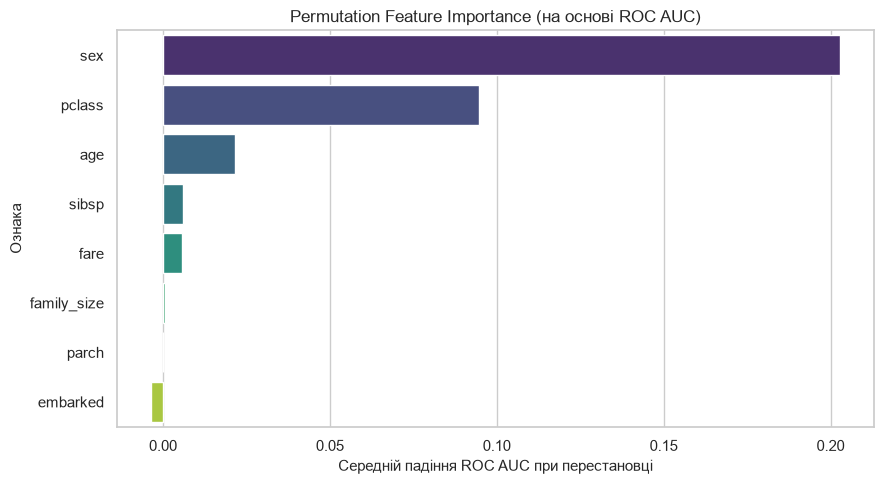

In [12]:
# Розрахунок Permutation Importance на тестовій вибірці за ROC AUC
perm_importance = permutation_importance(
    model, X_test, y_test, n_repeats=10, random_state=SEED, scoring="roc_auc"
)

# Формування таблиці значущості ознак
perm_df = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_importance.importances_mean,
    "importance_std": perm_importance.importances_std
}).sort_values("importance_mean", ascending=False)

print("--- Permutation Importance (Варіант 10) ---")
display(perm_df.round(4))

# Збереження у CSV
perm_df.to_csv("permutation_importance.csv", index=False)

# Візуалізація важливості ознак
plt.figure(figsize=(9, 5))
sns.barplot(
    data=perm_df, x="importance_mean", y="feature",
    palette="viridis", errorbar=None
)
plt.title("Permutation Feature Importance (на основі ROC AUC)", fontsize=12)
plt.xlabel("Середній падіння ROC AUC при перестановці", fontsize=11)
plt.ylabel("Ознака", fontsize=11)
plt.tight_layout()

plt.savefig("fig4_permutation_importance.png", dpi=300)
plt.show()

### Аналіз 5 найважливіших ознак за Permutation Importance (Варіант 10)

1. **`sex` (Стать):** Перестановка значень статі викликає найбільше падіння метрики якості моделі. Це свідчить про те, що стать має найсильнішу прогностичну вагу в моделі.
2. **`pclass` (Клас квитка):** Друга за важливістю ознака. Соціально-економічний клас квитка суттєво впливає на здатності моделі розділяти класи.
3. **`fare` (Вартість квитка):** Ознака корелює із забезпеченням пасажира та розташуванням каюти на борту.
4. **`age` (Вік):** Фізичний вік є суттєвим фактором, оскільки діти мали пріоритет під час посадки у рятувальні шлюпки.
5. **`family_size` (Розмір родини):** Склад родини додає інформацію про можливість взаємодопомоги пасажирів під час евакуації.

> **Важливе застереження (Non-causal note):** Отримані значення Permutation Importance описують **виключно асоціативний і прогностичний у внесок ознак у математичну модель**, а не безпосередній причинно-наслідковий зв'язок (Correlation / Feature Importance $\neq$ Causation).

## Загальний висновок

У ході виконання лабораторної роботи №4 було побудовано та оцінено модель бінарної класифікації на основі Логістичної Регресії для датасету Titanic.

* **Результативність:** Модель досягла $Accuracy \approx 80.4\%$, $F1 \approx 0.735$ та $ROC\ AUC \approx 0.850$, що суттєво перевищує константну базову модель ($Accuracy = 61.5\%$).
* **Контроль витоку:** Завдяки побудові `Pipeline` та `ColumnTransformer` усі процедури імпутації та стандартизації виконувалися виключно на `X_train`.
* **Індивідуальне дослідження (Варіант 10):** Аналіз Permutation Importance підтвердив, що найбільш прогностично цінними ознаками для моделі є `sex` та `pclass`.